# BCSC 浅海信道稀疏性与可辨识性诊断

**数据：** `Voyage_Ori_01 / PulseTrain_014`，共9个 click；重点记录为 `Click_008`。

本 Notebook 不修改原 BCSC Notebook，而是对浅海条件下的两个关键问题做独立实验：

1. 信道激活 $h$ 是否在当前时间分辨率下可压缩；
2. 0.118 ms 等早期结构是否会在 click 原子与多径激活之间转移。

实验包括：

- 5种原子长度 × 5种稀疏强度的二维扫描；
- 数据驱动选择折中配置，然后进行8次多初值检验；
- $K_{90}$、$K_{95}$、Hoyer sparsity、Gini 系数和路径簇能量诊断；
- 残差包络、残差自相关及残差—原子互相关；
- 对9个 click 进行共享原子的联合 BCSC，检验跨 click 复现性。

> 这是方法诊断，不使用真实发射 click 或已知信道。单通道盲分解仍然存在整体时移、符号、尺度与源/信道分解不唯一性。


In [1]:
from pathlib import Path
import csv
import json
import math
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.io import wavfile
from scipy.signal import (
    butter, sosfiltfilt, windows, fftconvolve, correlate,
    find_peaks, hilbert, welch,
)

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable=None, total=None, desc=None, **kwargs):
        return iterable if iterable is not None else None

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 125

PROJECT_ROOT = Path(r"D:\Project_Github\Indo-Pacific-humpback-dolphin")
DATA_DIR = PROJECT_ROOT / r"00_Data\Positive_Clicks_3500\Voyage_Ori_01\PulseTrain_014"
BASELINE_JSON = PROJECT_ROOT / r"18_多径提取算法\BCSC_010_results\bcsc_paths.json"
OUTPUT_DIR = PROJECT_ROOT / r"18_多径提取算法\BCSC_011_shallow_water_diagnostic_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CLICK = "Click_008"
LOWCUT_HZ, HIGHCUT_HZ = 20_000.0, 190_000.0
FILTER_ORDER = 6
ATOM_DURATIONS_MS = np.array([0.08, 0.12, 0.18, 0.25, 0.40])
LAMBDA_RATIOS = np.array([0.01875, 0.0375, 0.075, 0.15, 0.30])  # 0.25–4 × 原基线0.075
GRID_OUTER, GRID_FISTA, GRID_DICT = 12, 45, 10
FINAL_OUTER, FINAL_FISTA, FINAL_DICT = 24, 90, 20
MULTISTART_RUNS = 8
PEAK_RATIO = 0.015
MIN_PATH_DISTANCE_MS = 0.035
PATH_MATCH_TOLERANCE_MS = 0.035
ENERGY_BLOCK_MS = 0.08
RANDOM_SEED = 20260813

wav_paths = sorted(DATA_DIR.glob("Click_*/*.wav"))
if len(wav_paths) < 2:
    raise RuntimeError(f"需要至少2个 click，当前找到 {len(wav_paths)} 个：{DATA_DIR}")
if not BASELINE_JSON.exists():
    raise FileNotFoundError(BASELINE_JSON)

baseline = json.loads(BASELINE_JSON.read_text(encoding="utf-8"))
reference_delays = np.asarray([p["relative_delay_ms"] for p in baseline["paths"][1:]], dtype=float)
print(f"输入 click 数：{len(wav_paths)}")
print(f"参考候选延迟：{np.round(reference_delays, 4).tolist()} ms")
print(f"输出目录：{OUTPUT_DIR}")


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Chico\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


输入 click 数：9
参考候选延迟：[0.1181, 0.2361, 1.2691, 2.6997] ms
输出目录：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_011_shallow_water_diagnostic_results


D:\Python3_13\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 数据读取与可比较预处理

所有 click 均使用与原 BCSC 一致的20–190 kHz零相位带通、去直流、边缘渐变和单 click 峰值归一化。这保证参数扫描与原结果的差异主要来自 BCSC 配置。


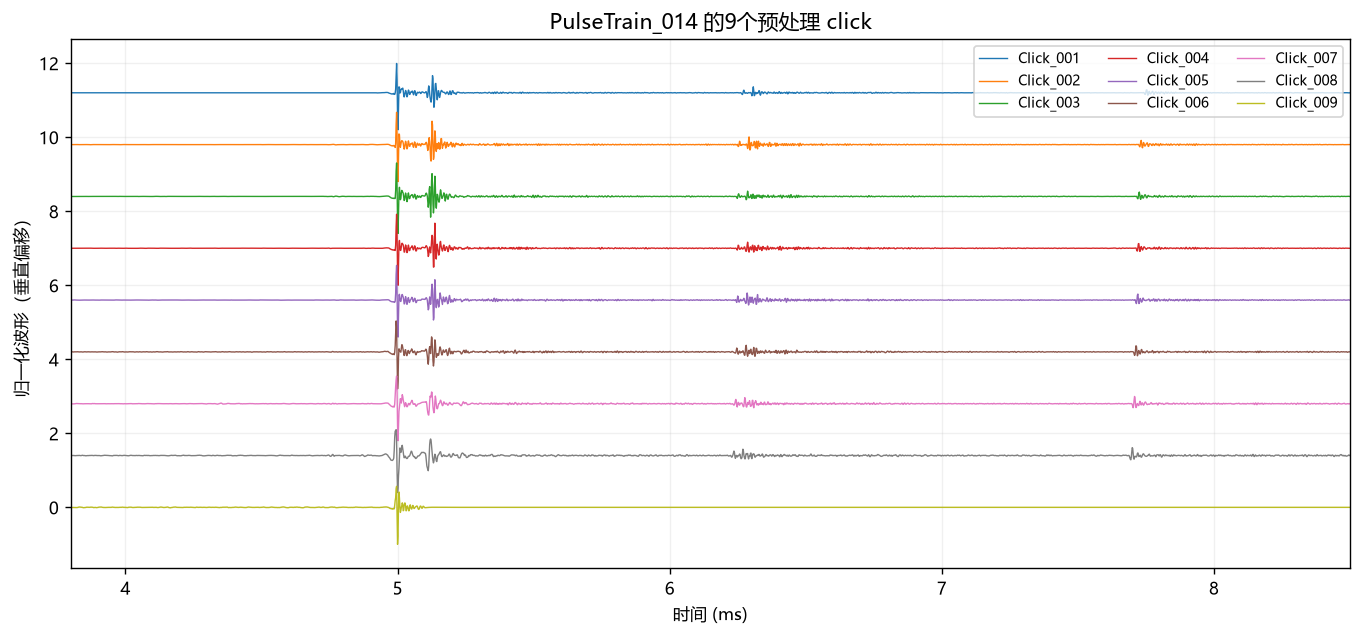

采样率：576,000 Hz；单条长度：10.002 ms


In [2]:
def read_and_preprocess(path):
    fs, raw = wavfile.read(path)
    if raw.ndim == 2:
        raw = raw.mean(axis=1)
    if np.issubdtype(raw.dtype, np.integer):
        scale = max(abs(np.iinfo(raw.dtype).min), np.iinfo(raw.dtype).max)
        signal = raw.astype(np.float64) / scale
    else:
        signal = raw.astype(np.float64)
    signal -= np.mean(signal)
    nyquist = fs / 2.0
    sos = butter(
        FILTER_ORDER,
        [LOWCUT_HZ / nyquist, HIGHCUT_HZ / nyquist],
        btype="bandpass", output="sos",
    )
    signal = sosfiltfilt(sos, signal)
    signal *= windows.tukey(len(signal), alpha=0.02)
    signal /= np.max(np.abs(signal)) + 1e-12
    return int(fs), signal

signals, labels = [], []
sample_rate = None
for path in wav_paths:
    fs_i, signal = read_and_preprocess(path)
    if sample_rate is None:
        sample_rate = fs_i
    if fs_i != sample_rate:
        raise ValueError("同一 click train 采样率不一致")
    signals.append(signal)
    labels.append(path.parent.name)
min_length = min(map(len, signals))
signals = np.asarray([x[:min_length] for x in signals])
target_position = labels.index(TARGET_CLICK)
y = signals[target_position]
fs = sample_rate
t_ms = np.arange(min_length) / fs * 1e3

fig, ax = plt.subplots(figsize=(11, 5.2))
offsets = np.arange(len(signals))[::-1] * 1.4
for label, signal, offset in zip(labels, signals, offsets):
    ax.plot(t_ms, signal + offset, lw=0.8, label=label)
ax.set(xlabel="时间 (ms)", ylabel="归一化波形（垂直偏移）",
       title="PulseTrain_014 的9个预处理 click")
ax.set_xlim(3.8, 8.5)
ax.grid(alpha=0.18)
ax.legend(ncol=3, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_click_train_waveforms.png", dpi=220, bbox_inches="tight")
plt.show()
print(f"采样率：{fs:,} Hz；单条长度：{min_length / fs * 1e3:.3f} ms")


## 2. BCSC 核心算法

保持原 Notebook 的单原子模型：

$$\min_{d,a}\frac12\lVert y-d*a\rVert_2^2+\lambda\lVert a\rVert_1,
\qquad \lVert d\rVert_2=1.$$

稀疏编码使用 FISTA，原子使用投影梯度更新。联合版本中9条记录共享一个原子，但各自拥有独立激活。


In [3]:
def soft_threshold(z, threshold):
    return np.sign(z) * np.maximum(np.abs(z) - threshold, 0.0)

def reconstruct(atom, activation, signal_len):
    return fftconvolve(activation, atom, mode="full")[:signal_len]

def adjoint_atom(residual, atom, activation_len):
    return correlate(residual, atom, mode="valid", method="fft")[:activation_len]

def adjoint_code(residual, activation, atom_length):
    return correlate(residual, activation, mode="valid", method="fft")[:atom_length]

def spectral_lipschitz(kernel, output_len):
    n_fft = 1 << int(np.ceil(np.log2(max(2, output_len))))
    return float(np.max(np.abs(np.fft.rfft(kernel, n=n_fft)) ** 2) + 1e-10)

def normalize_atom(atom):
    atom = np.asarray(atom, dtype=float) - np.mean(atom)
    norm = np.linalg.norm(atom)
    if norm < 1e-12:
        raise RuntimeError("原子范数过小")
    atom /= norm
    if atom[np.argmax(np.abs(atom))] < 0:
        atom = -atom
    return atom

def peak_atom(signal, atom_length, jitter=0):
    peak = int(np.argmax(np.abs(signal))) + int(jitter)
    half = atom_length // 2
    padded = np.pad(signal, (atom_length, atom_length))
    start = peak + atom_length - half
    atom = padded[start:start + atom_length].copy()
    atom *= windows.tukey(atom_length, alpha=0.35)
    return normalize_atom(atom)

def make_initializer(signal, atom_length, start_index, rng):
    if start_index == 0:
        return peak_atom(signal, atom_length)
    max_jitter = max(2, atom_length // 5)
    jitter = int(rng.integers(-max_jitter, max_jitter + 1))
    atom = peak_atom(signal, atom_length, jitter=jitter)
    noise = rng.normal(size=atom_length) * (0.04 + 0.01 * start_index)
    return normalize_atom((atom + noise) * windows.tukey(atom_length, alpha=0.25))

def fista_sparse_code(signal, atom, lam, x0=None, n_iter=90):
    activation_len = len(signal) - len(atom) + 1
    x = np.zeros(activation_len) if x0 is None else x0.copy()
    z, momentum = x.copy(), 1.0
    lipschitz = spectral_lipschitz(atom, len(signal))
    for _ in range(n_iter):
        residual = reconstruct(atom, z, len(signal)) - signal
        gradient = adjoint_atom(residual, atom, activation_len)
        x_new = soft_threshold(z - gradient / lipschitz, lam / lipschitz)
        momentum_new = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * momentum * momentum))
        z = x_new + ((momentum - 1.0) / momentum_new) * (x_new - x)
        x, momentum = x_new, momentum_new
    return x

def update_atom(signal, activation, atom, n_iter=20):
    if np.linalg.norm(activation) < 1e-12:
        return atom
    step = 0.8 / spectral_lipschitz(activation, len(signal))
    updated = atom.copy()
    taper = windows.tukey(len(atom), alpha=0.20)
    for _ in range(n_iter):
        residual = reconstruct(updated, activation, len(signal)) - signal
        gradient = adjoint_code(residual, activation, len(atom))
        updated = normalize_atom((updated - step * gradient) * taper)
    return updated

def update_shared_atom(signal_matrix, activations, atom, n_iter=20):
    denominator = sum(spectral_lipschitz(a, signal_matrix.shape[1]) for a in activations)
    if denominator <= 1e-12:
        return atom
    step = 0.75 / denominator
    updated = atom.copy()
    taper = windows.tukey(len(atom), alpha=0.20)
    for _ in range(n_iter):
        gradient = np.zeros_like(updated)
        for signal, activation in zip(signal_matrix, activations):
            residual = reconstruct(updated, activation, len(signal)) - signal
            gradient += adjoint_code(residual, activation, len(updated))
        updated = normalize_atom((updated - step * gradient) * taper)
    return updated

def shift_atom_and_codes(atom, activations):
    center = len(atom) // 2
    shift = center - int(np.argmax(np.abs(atom)))
    shifted_atom = np.roll(atom, shift)
    if shift > 0:
        shifted_atom[:shift] = 0.0
    elif shift < 0:
        shifted_atom[shift:] = 0.0
    shifted_atom = normalize_atom(shifted_atom)
    shifted_codes = []
    for activation in activations:
        shifted = np.roll(activation, -shift)
        if shift > 0:
            shifted[-shift:] = 0.0
        elif shift < 0:
            shifted[:-shift] = 0.0
        shifted_codes.append(shifted)
    return shifted_atom, shifted_codes

def bcsc(signal, atom_length, lambda_ratio, outer_iterations, fista_iterations,
         dictionary_iterations, initial_atom=None):
    atom = peak_atom(signal, atom_length) if initial_atom is None else normalize_atom(initial_atom)
    activation = np.zeros(len(signal) - atom_length + 1)
    for iteration in range(outer_iterations):
        max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
        anneal = 1.8 - 0.8 * iteration / max(outer_iterations - 1, 1)
        lam = lambda_ratio * anneal * max_corr
        activation = fista_sparse_code(signal, atom, lam, activation, fista_iterations)
        atom = update_atom(signal, activation, atom, dictionary_iterations)
        atom, [activation] = shift_atom_and_codes(atom, [activation])
    max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
    lam = lambda_ratio * max_corr
    activation = fista_sparse_code(signal, atom, lam, activation, 2 * fista_iterations)
    estimate = reconstruct(atom, activation, len(signal))
    return atom, activation, estimate

def joint_bcsc(signal_matrix, atom_length, lambda_ratio, outer_iterations,
               fista_iterations, dictionary_iterations):
    anchor = np.mean(signal_matrix, axis=0)
    atom = peak_atom(anchor, atom_length)
    activations = [np.zeros(signal_matrix.shape[1] - atom_length + 1) for _ in signal_matrix]
    for iteration in range(outer_iterations):
        anneal = 1.8 - 0.8 * iteration / max(outer_iterations - 1, 1)
        new_codes = []
        for signal, activation in zip(signal_matrix, activations):
            max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
            lam = lambda_ratio * anneal * max_corr
            new_codes.append(fista_sparse_code(signal, atom, lam, activation, fista_iterations))
        activations = new_codes
        atom = update_shared_atom(signal_matrix, activations, atom, dictionary_iterations)
        atom, activations = shift_atom_and_codes(atom, activations)
    final_codes, estimates = [], []
    for signal, activation in zip(signal_matrix, activations):
        max_corr = np.max(np.abs(adjoint_atom(signal, atom, len(activation))))
        activation = fista_sparse_code(signal, atom, lambda_ratio * max_corr,
                                        activation, 2 * fista_iterations)
        final_codes.append(activation)
        estimates.append(reconstruct(atom, activation, len(signal)))
    return atom, final_codes, np.asarray(estimates)


## 3. 诊断指标与候选路径匹配

- $K_{90}$/$K_{95}$：解释90%/95%激活能量所需的最少系数数；
- Hoyer sparsity：越接1越稀疏；
- Gini：越接1表示能量越集中；
- 块 $K_{90}$：将激活按0.08 ms分块后，解释90%能量的块数；
- 残差原子相关：残差中是否仍存在未解释的 click 样结构。


In [4]:
def effective_count(values, fraction):
    energy = np.sort(np.abs(values) ** 2)[::-1]
    if energy.sum() <= 1e-15:
        return 0
    return int(np.searchsorted(np.cumsum(energy), fraction * energy.sum()) + 1)

def hoyer_sparsity(values):
    values = np.abs(np.asarray(values))
    n = len(values)
    if n <= 1 or np.linalg.norm(values) <= 1e-15:
        return np.nan
    return float((np.sqrt(n) - values.sum() / np.linalg.norm(values)) / (np.sqrt(n) - 1.0))

def gini_coefficient(values):
    values = np.sort(np.abs(np.asarray(values)))
    if values.sum() <= 1e-15:
        return np.nan
    n = len(values)
    return float((2 * np.sum((np.arange(n) + 1) * values) / (n * values.sum())) - (n + 1) / n)

def block_energy_counts(activation, block_samples, fraction=0.90):
    pad = (-len(activation)) % block_samples
    padded = np.pad(activation, (0, pad))
    block_energy = np.sum(padded.reshape(-1, block_samples) ** 2, axis=1)
    return effective_count(np.sqrt(block_energy), fraction), block_energy

def extract_relative_peaks(activation, sample_rate, atom_length,
                           peak_ratio=PEAK_RATIO, min_distance_ms=MIN_PATH_DISTANCE_MS):
    magnitude = np.abs(activation)
    distance = max(1, int(round(min_distance_ms * 1e-3 * sample_rate)))
    peaks, _ = find_peaks(magnitude, height=peak_ratio * (magnitude.max() + 1e-15), distance=distance)
    global_peak = int(np.argmax(magnitude))
    if global_peak not in peaks:
        peaks = np.sort(np.append(peaks, global_peak))
    arrivals = peaks + atom_length // 2
    direct_position = int(np.argmax(magnitude[peaks]))
    direct_arrival = arrivals[direct_position]
    delays = (arrivals - direct_arrival) / sample_rate * 1e3
    keep = delays >= -1e-12
    order = np.argsort(delays[keep])
    return peaks[keep][order], delays[keep][order], magnitude[peaks[keep][order]] / (magnitude[peaks[direct_position]] + 1e-15)

def summarize_fit(signal, atom, activation, estimate):
    residual = signal - estimate
    explained = 1.0 - np.dot(residual, residual) / (np.dot(signal, signal) + 1e-15)
    block_samples = max(1, int(round(ENERGY_BLOCK_MS * 1e-3 * fs)))
    block_k90, _ = block_energy_counts(activation, block_samples, 0.90)
    direct_index = int(np.argmax(np.abs(activation)))
    exclusion = max(1, int(round(0.08e-3 * fs)))
    tail_activation = activation.copy()
    tail_activation[max(0, direct_index-exclusion):min(len(activation), direct_index+exclusion+1)] = 0.0
    tail_energy_fraction = float(
        np.dot(tail_activation, tail_activation) / (np.dot(activation, activation) + 1e-15)
    )
    tail_block_k90, _ = block_energy_counts(tail_activation, block_samples, 0.90)
    residual_corr = correlate(residual, atom, mode="valid", method="fft")
    normalized_corr = np.max(np.abs(residual_corr)) / (
        np.linalg.norm(residual) * np.linalg.norm(atom) + 1e-15
    )
    peaks, delays, amplitudes = extract_relative_peaks(activation, fs, len(atom))
    return {
        "explained_variance": float(explained),
        "k90": effective_count(activation, 0.90),
        "k95": effective_count(activation, 0.95),
        "block_k90": int(block_k90),
        "tail_k90": effective_count(tail_activation, 0.90),
        "tail_block_k90": int(tail_block_k90),
        "tail_energy_fraction": tail_energy_fraction,
        "hoyer": hoyer_sparsity(activation),
        "gini": gini_coefficient(activation),
        "residual_atom_correlation": float(normalized_corr),
        "n_detected_peaks": int(len(peaks)),
        "delays_ms": delays.tolist(),
        "relative_amplitudes": amplitudes.tolist(),
    }

def match_reference_delays(delays, references, tolerance=PATH_MATCH_TOLERANCE_MS):
    delays = np.asarray(delays)
    result = []
    for reference in references:
        if len(delays) == 0:
            result.append(np.nan)
            continue
        nearest = int(np.argmin(np.abs(delays - reference)))
        result.append(float(delays[nearest]) if abs(delays[nearest] - reference) <= tolerance else np.nan)
    return result


## 4. 原子长度—稀疏强度二维扫描

扫描范围为0.08–0.40 ms与基线 $\lambda$ 的0.25–4倍。为避免只按重构率选择过拟合模型，折中配置按如下规则自动选择：

1. 先保留解释方差距扫描最优值不超过3个百分点的配置；
2. 在其中最小化块 $K_{90}$；
3. 若并列，最小化残差—原子相关，再选择更高解释率。

这是明确的数据选择规则，不将它解释为真实信道模型的证明。


In [5]:
total_fits = len(ATOM_DURATIONS_MS) * len(LAMBDA_RATIOS) + MULTISTART_RUNS + 1
overall = tqdm(total=total_fits, desc="BCSC浅海诊断总体进度", unit="拟合")
grid_results = []
for atom_ms in ATOM_DURATIONS_MS:
    atom_length = max(15, int(round(atom_ms * 1e-3 * fs)))
    if atom_length % 2 == 0:
        atom_length += 1
    for lambda_ratio in LAMBDA_RATIOS:
        atom, activation, estimate = bcsc(
            y, atom_length, float(lambda_ratio),
            GRID_OUTER, GRID_FISTA, GRID_DICT,
        )
        metrics = summarize_fit(y, atom, activation, estimate)
        matched = match_reference_delays(metrics["delays_ms"], reference_delays)
        grid_results.append({
            "atom_duration_ms": atom_length / fs * 1e3,
            "lambda_ratio": float(lambda_ratio),
            **{k: v for k, v in metrics.items() if k not in ("delays_ms", "relative_amplitudes")},
            "delays_ms": metrics["delays_ms"],
            "relative_amplitudes": metrics["relative_amplitudes"],
            "matched_delays_ms": matched,
        })
        overall.update(1)

max_explained = max(row["explained_variance"] for row in grid_results)
eligible = [row for row in grid_results if row["explained_variance"] >= max_explained - 0.03]
selected = sorted(
    eligible,
    key=lambda row: (row["block_k90"], row["residual_atom_correlation"], -row["explained_variance"]),
)[0]
selected_atom_ms = selected["atom_duration_ms"]
selected_lambda = selected["lambda_ratio"]

scalar_fields = [
    "explained_variance", "k90", "block_k90", "hoyer",
    "residual_atom_correlation", "n_detected_peaks",
]
matrices = {
    field: np.asarray([
        [next(row[field] for row in grid_results
              if np.isclose(row["atom_duration_ms"], max(15, int(round(a * 1e-3 * fs)) + (int(round(a * 1e-3 * fs)) % 2 == 0)) / fs * 1e3)
              and np.isclose(row["lambda_ratio"], lam))
         for lam in LAMBDA_RATIOS]
        for a in ATOM_DURATIONS_MS
    ], dtype=float)
    for field in scalar_fields
}

print(f"扫描最高解释方差：{max_explained:.4f}")
print(f"折中配置：原子 {selected_atom_ms:.4f} ms，lambda_ratio={selected_lambda:.5f}")
print(f"折中配置指标：{selected}")


BCSC浅海诊断总体进度:   0%|          | 0/34 [00:00<?, ?拟合/s]

BCSC浅海诊断总体进度:   3%|▎         | 1/34 [00:00<00:07,  4.39拟合/s]

BCSC浅海诊断总体进度:   6%|▌         | 2/34 [00:00<00:07,  4.36拟合/s]

BCSC浅海诊断总体进度:   9%|▉         | 3/34 [00:00<00:07,  4.35拟合/s]

BCSC浅海诊断总体进度:  12%|█▏        | 4/34 [00:00<00:07,  4.23拟合/s]

...

BCSC浅海诊断总体进度:  65%|██████▍   | 22/34 [00:04<00:02,  4.46拟合/s]

BCSC浅海诊断总体进度:  68%|██████▊   | 23/34 [00:05<00:02,  4.49拟合/s]

BCSC浅海诊断总体进度:  71%|███████   | 24/34 [00:05<00:02,  3.95拟合/s]

BCSC浅海诊断总体进度:  74%|███████▎  | 25/34 [00:06<00:02,  3.16拟合/s]

扫描最高解释方差：0.9473
折中配置：原子 0.4010 ms，lambda_ratio=0.01875
折中配置指标：{'atom_duration_ms': 0.4010416666666667, 'lambda_ratio': 0.01875, 'explained_variance': 0.9423474492633748, 'k90': 1, 'k95': 1, 'block_k90': 1, 'tail_k90': 8, 'tail_block_k90': 4, 'tail_energy_fraction': 0.023299871799720213, 'hoyer': 0.9918911173838568, 'gini': 0.9985781111878644, 'residual_atom_correlation': 0.07422270812997472, 'n_detected_peaks': 4, 'delays_ms': [0.0, 0.23611111111111113, 1.2690972222222223, 2.6996527777777777], 'relative_amplitudes': [0.9999999999999997, 0.04238600843716652, 0.0629998813123788, 0.08784291787280968], 'matched_delays_ms': [nan, 0.23611111111111113, 1.2690972222222223, 2.6996527777777777]}


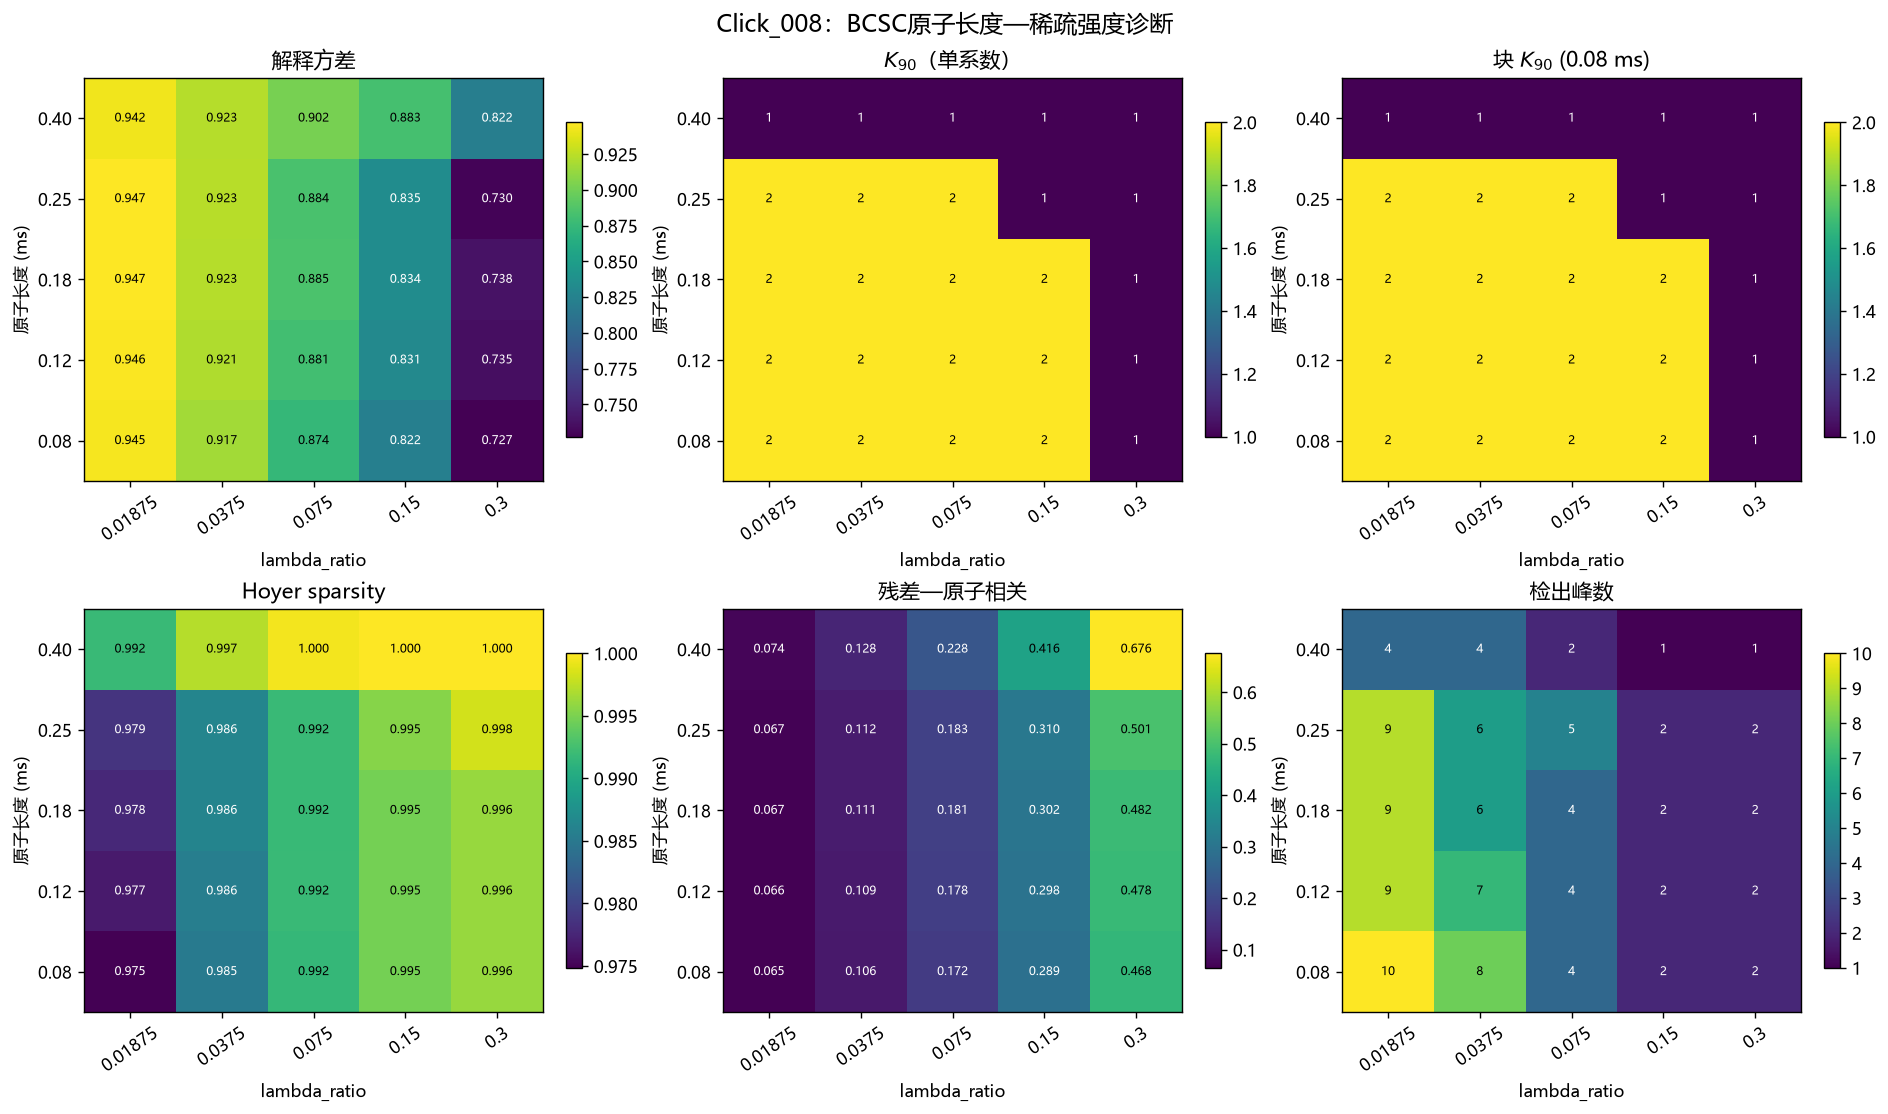

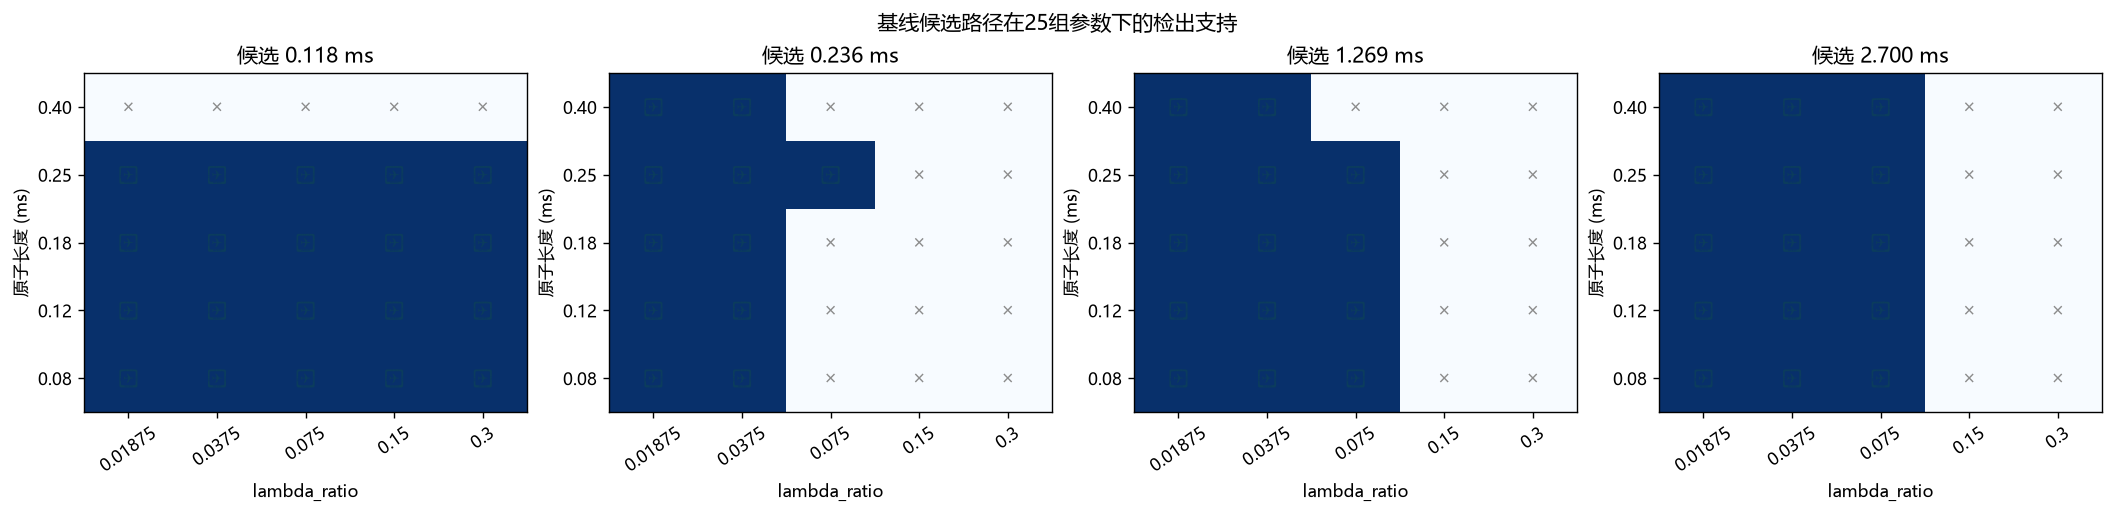

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.8), constrained_layout=True)
display_specs = [
    ("explained_variance", "解释方差", ".3f"),
    ("k90", "$K_{90}$（单系数）", ".0f"),
    ("block_k90", "块 $K_{90}$ (0.08 ms)", ".0f"),
    ("hoyer", "Hoyer sparsity", ".3f"),
    ("residual_atom_correlation", "残差—原子相关", ".3f"),
    ("n_detected_peaks", "检出峰数", ".0f"),
]
for ax, (field, title, fmt) in zip(axes.flat, display_specs):
    matrix = matrices[field]
    image = ax.imshow(matrix, aspect="auto", origin="lower", cmap="viridis")
    ax.set_xticks(range(len(LAMBDA_RATIOS)), [f"{v:.4g}" for v in LAMBDA_RATIOS], rotation=35)
    ax.set_yticks(range(len(ATOM_DURATIONS_MS)), [f"{v:.2f}" for v in ATOM_DURATIONS_MS])
    ax.set(xlabel="lambda_ratio", ylabel="原子长度 (ms)", title=title)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            color = "white" if Normalize(matrix.min(), matrix.max() + 1e-15)(matrix[i, j]) < 0.52 else "black"
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", fontsize=7, color=color)
    fig.colorbar(image, ax=ax, shrink=0.78)
fig.suptitle("Click_008：BCSC原子长度—稀疏强度诊断", fontsize=14)
fig.savefig(OUTPUT_DIR / "02_parameter_grid_metrics.png", dpi=220, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(reference_delays), figsize=(4.2 * len(reference_delays), 4), constrained_layout=True)
if len(reference_delays) == 1:
    axes = [axes]
for ref_idx, (ax, reference) in enumerate(zip(axes, reference_delays)):
    support = np.asarray([
        [float(np.isfinite(next(row["matched_delays_ms"][ref_idx] for row in grid_results
                                 if np.isclose(row["atom_duration_ms"], max(15, int(round(a * 1e-3 * fs)) + (int(round(a * 1e-3 * fs)) % 2 == 0)) / fs * 1e3)
                                 and np.isclose(row["lambda_ratio"], lam))))
         for lam in LAMBDA_RATIOS]
        for a in ATOM_DURATIONS_MS
    ])
    ax.imshow(support, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LAMBDA_RATIOS)), [f"{v:.4g}" for v in LAMBDA_RATIOS], rotation=35)
    ax.set_yticks(range(len(ATOM_DURATIONS_MS)), [f"{v:.2f}" for v in ATOM_DURATIONS_MS])
    ax.set(xlabel="lambda_ratio", ylabel="原子长度 (ms)", title=f"候选 {reference:.3f} ms")
    for i in range(support.shape[0]):
        for j in range(support.shape[1]):
            ax.text(j, i, "✓" if support[i, j] else "×", ha="center", va="center",
                    color="#0B3C5D" if support[i, j] else "0.55", fontsize=11)
fig.suptitle("基线候选路径在25组参数下的检出支持")
fig.savefig(OUTPUT_DIR / "03_candidate_support_grid.png", dpi=220, bbox_inches="tight")
plt.show()


## 5. 折中配置的多初值稳定性

参数扫描只使用主峰初值。本节对自动选出的折中配置运行8个确定性或随机扰动初值，检查非凸优化是否会稳定返回同一结构。


BCSC浅海诊断总体进度:  76%|███████▋  | 26/34 [00:13<00:18,  2.33s/拟合]

BCSC浅海诊断总体进度:  79%|███████▉  | 27/34 [00:14<00:15,  2.20s/拟合]

BCSC浅海诊断总体进度:  82%|████████▏ | 28/34 [00:16<00:12,  2.10s/拟合]

BCSC浅海诊断总体进度:  85%|████████▌ | 29/34 [00:18<00:10,  2.03s/拟合]

BCSC浅海诊断总体进度:  88%|████████▊ | 30/34 [00:20<00:08,  2.01s/拟合]

BCSC浅海诊断总体进度:  91%|█████████ | 31/34 [00:22<00:05,  1.95s/拟合]

BCSC浅海诊断总体进度:  94%|█████████▍| 32/34 [00:24<00:03,  1.93s/拟合]

BCSC浅海诊断总体进度:  97%|█████████▋| 33/34 [00:26<00:01,  1.93s/拟合]

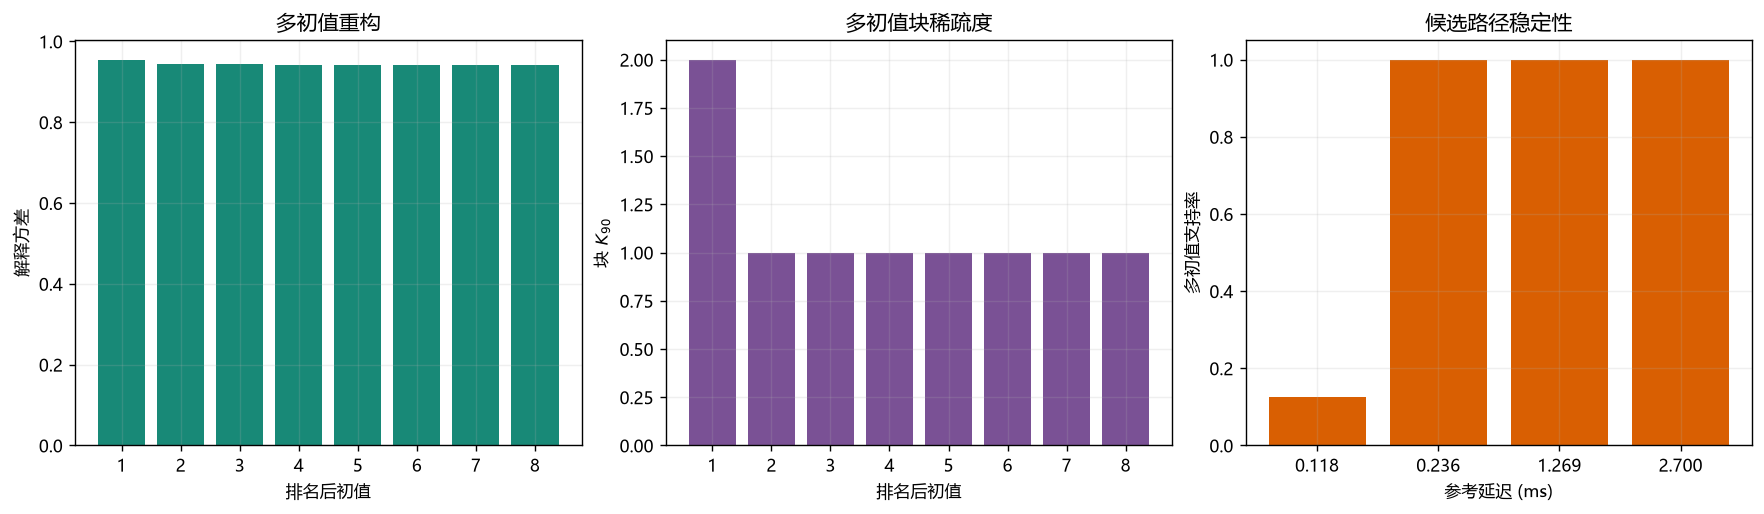

多初值候选支持率：
  0.1181 ms: 12.5%; 匹配值=[0.1146]
  0.2361 ms: 100.0%; 匹配值=[0.2361, 0.2361, 0.2361, 0.2361, 0.2361, 0.2361, 0.2361, 0.2361]
  1.2691 ms: 100.0%; 匹配值=[1.2847, 1.2691, 1.2691, 1.2691, 1.2691, 1.2691, 1.2691, 1.2691]
  2.6997 ms: 100.0%; 匹配值=[2.6997, 2.6997, 2.6997, 2.6997, 2.6997, 2.6997, 2.6997, 2.6997]


In [7]:
rng = np.random.default_rng(RANDOM_SEED)
selected_atom_length = max(15, int(round(selected_atom_ms * 1e-3 * fs)))
if selected_atom_length % 2 == 0:
    selected_atom_length += 1
multistart = []
for start in range(MULTISTART_RUNS):
    initial = make_initializer(y, selected_atom_length, start, rng)
    atom, activation, estimate = bcsc(
        y, selected_atom_length, selected_lambda,
        FINAL_OUTER, FINAL_FISTA, FINAL_DICT,
        initial_atom=initial,
    )
    metrics = summarize_fit(y, atom, activation, estimate)
    multistart.append({"start": start + 1, "atom": atom, "activation": activation,
                       "estimate": estimate, "metrics": metrics})
    overall.update(1)

multistart.sort(key=lambda item: item["metrics"]["explained_variance"], reverse=True)
best = multistart[0]
best_atom = best["atom"]
best_activation = best["activation"]
best_estimate = best["estimate"]
best_metrics = best["metrics"]

support_counts = []
matched_values = []
for reference in reference_delays:
    values = []
    for run in multistart:
        match = match_reference_delays(run["metrics"]["delays_ms"], [reference])[0]
        if np.isfinite(match):
            values.append(match)
    support_counts.append(len(values) / MULTISTART_RUNS)
    matched_values.append(values)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
axes[0].bar(range(1, MULTISTART_RUNS + 1),
            [x["metrics"]["explained_variance"] for x in multistart], color="#188977")
axes[0].set(xlabel="排名后初值", ylabel="解释方差", title="多初值重构")
axes[1].bar(range(1, MULTISTART_RUNS + 1),
            [x["metrics"]["block_k90"] for x in multistart], color="#7A5195")
axes[1].set(xlabel="排名后初值", ylabel="块 $K_{90}$", title="多初值块稀疏度")
axes[2].bar([f"{x:.3f}" for x in reference_delays], support_counts, color="#D95F02")
axes[2].set(xlabel="参考延迟 (ms)", ylabel="多初值支持率", ylim=(0, 1.05), title="候选路径稳定性")
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "04_multistart_stability.png", dpi=220, bbox_inches="tight")
plt.show()

print("多初值候选支持率：")
for reference, support, values in zip(reference_delays, support_counts, matched_values):
    print(f"  {reference:.4f} ms: {support:.1%}; 匹配值={np.round(values, 4).tolist()}")


## 6. 最优多初值解的有效稀疏度与残差结构

如果单原子点稀疏模型充分，大部分激活能量应由少数系数或时间块解释，且残差不应继续包含强 click 样相关结构。


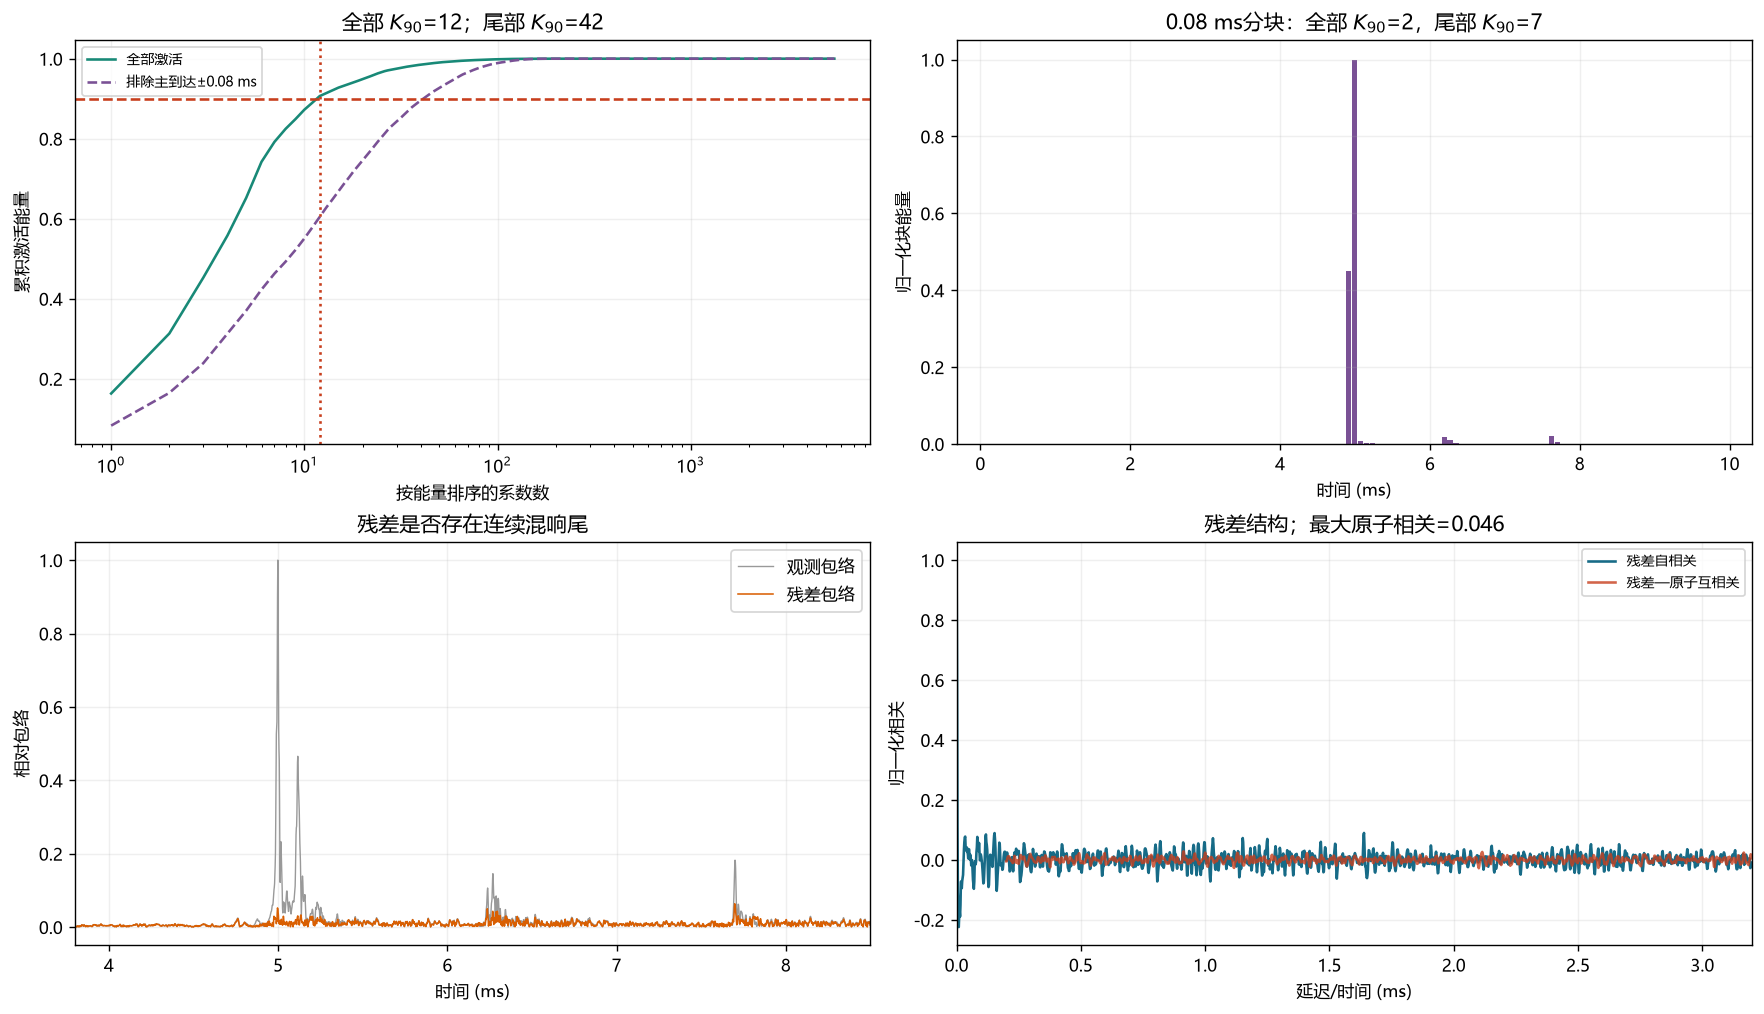

In [8]:
residual = y - best_estimate
activation_energy = np.abs(best_activation) ** 2
ranked_energy = np.sort(activation_energy)[::-1]
cumulative = np.cumsum(ranked_energy) / (ranked_energy.sum() + 1e-15)
direct_index = int(np.argmax(np.abs(best_activation)))
exclusion = max(1, int(round(0.08e-3 * fs)))
tail_activation = best_activation.copy()
tail_activation[max(0, direct_index-exclusion):min(len(best_activation), direct_index+exclusion+1)] = 0.0
tail_ranked_energy = np.sort(np.abs(tail_activation) ** 2)[::-1]
tail_cumulative = np.cumsum(tail_ranked_energy) / (tail_ranked_energy.sum() + 1e-15)
block_samples = max(1, int(round(ENERGY_BLOCK_MS * 1e-3 * fs)))
block_k90, block_energy = block_energy_counts(best_activation, block_samples, 0.90)
block_times = (np.arange(len(block_energy)) * block_samples + selected_atom_length // 2) / fs * 1e3

residual_env = np.abs(hilbert(residual))
residual_env /= np.max(np.abs(hilbert(y))) + 1e-15
signal_env = np.abs(hilbert(y)); signal_env /= signal_env.max() + 1e-15
autocorr = correlate(residual, residual, mode="full", method="fft")
autocorr = autocorr[len(residual)-1:]
autocorr /= autocorr[0] + 1e-15
ac_lags_ms = np.arange(len(autocorr)) / fs * 1e3
residual_atom_corr = correlate(residual, best_atom, mode="valid", method="fft")
residual_atom_corr /= np.linalg.norm(residual) * np.linalg.norm(best_atom) + 1e-15
corr_time_ms = (np.arange(len(residual_atom_corr)) + selected_atom_length // 2) / fs * 1e3

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
axes[0, 0].plot(np.arange(1, len(cumulative) + 1), cumulative, color="#188977", label="全部激活")
axes[0, 0].plot(np.arange(1, len(tail_cumulative) + 1), tail_cumulative,
                color="#7A5195", ls="--", label="排除主到达±0.08 ms")
axes[0, 0].axhline(0.90, color="#C73E1D", ls="--")
axes[0, 0].axvline(best_metrics["k90"], color="#C73E1D", ls=":")
axes[0, 0].set(xscale="log", xlabel="按能量排序的系数数", ylabel="累积激活能量",
               title=f"全部 $K_{{90}}$={best_metrics['k90']}；尾部 $K_{{90}}$={best_metrics['tail_k90']}")
axes[0, 0].legend(fontsize=8)
axes[0, 1].bar(block_times, block_energy / (block_energy.max() + 1e-15),
               width=ENERGY_BLOCK_MS * 0.86, color="#7A5195")
axes[0, 1].set(
    xlabel="时间 (ms)", ylabel="归一化块能量",
    title=(f"0.08 ms分块：全部 $K_{{90}}$={block_k90}，"
           f"尾部 $K_{{90}}$={best_metrics['tail_block_k90']}")
)
axes[1, 0].plot(t_ms, signal_env, color="0.6", lw=0.8, label="观测包络")
axes[1, 0].plot(t_ms, residual_env, color="#D95F02", lw=0.9, label="残差包络")
axes[1, 0].set(xlim=(3.8, 8.5), xlabel="时间 (ms)", ylabel="相对包络", title="残差是否存在连续混响尾")
axes[1, 0].legend()
axes[1, 1].plot(ac_lags_ms, autocorr, color="#176B87", label="残差自相关")
axes[1, 1].plot(corr_time_ms, residual_atom_corr, color="#C73E1D", alpha=0.8, label="残差—原子互相关")
axes[1, 1].set(xlim=(0, 3.2), xlabel="延迟/时间 (ms)", ylabel="归一化相关",
               title=f"残差结构；最大原子相关={best_metrics['residual_atom_correlation']:.3f}")
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "05_effective_sparsity_and_residual.png", dpi=220, bbox_inches="tight")
plt.show()


## 7. 9个 click 共享原子联合 BCSC

联合模型为

$$y_j=d*a_j+r_j,\qquad j=1,\ldots,9.$$

如果候选延迟来自稳定的 click 内部结构，它可能被共享原子吸收；如果来自传播多径，它更可能在多个独立激活中以类似延迟出现。但跨 click 几何变化也会使多径时延漂移，因此同时报告精确容差和较宽延迟带支持。


BCSC浅海诊断总体进度: 100%|██████████| 34/34 [00:36<00:00,  4.49s/拟合]

BCSC浅海诊断总体进度: 100%|██████████| 34/34 [00:36<00:00,  1.08s/拟合]

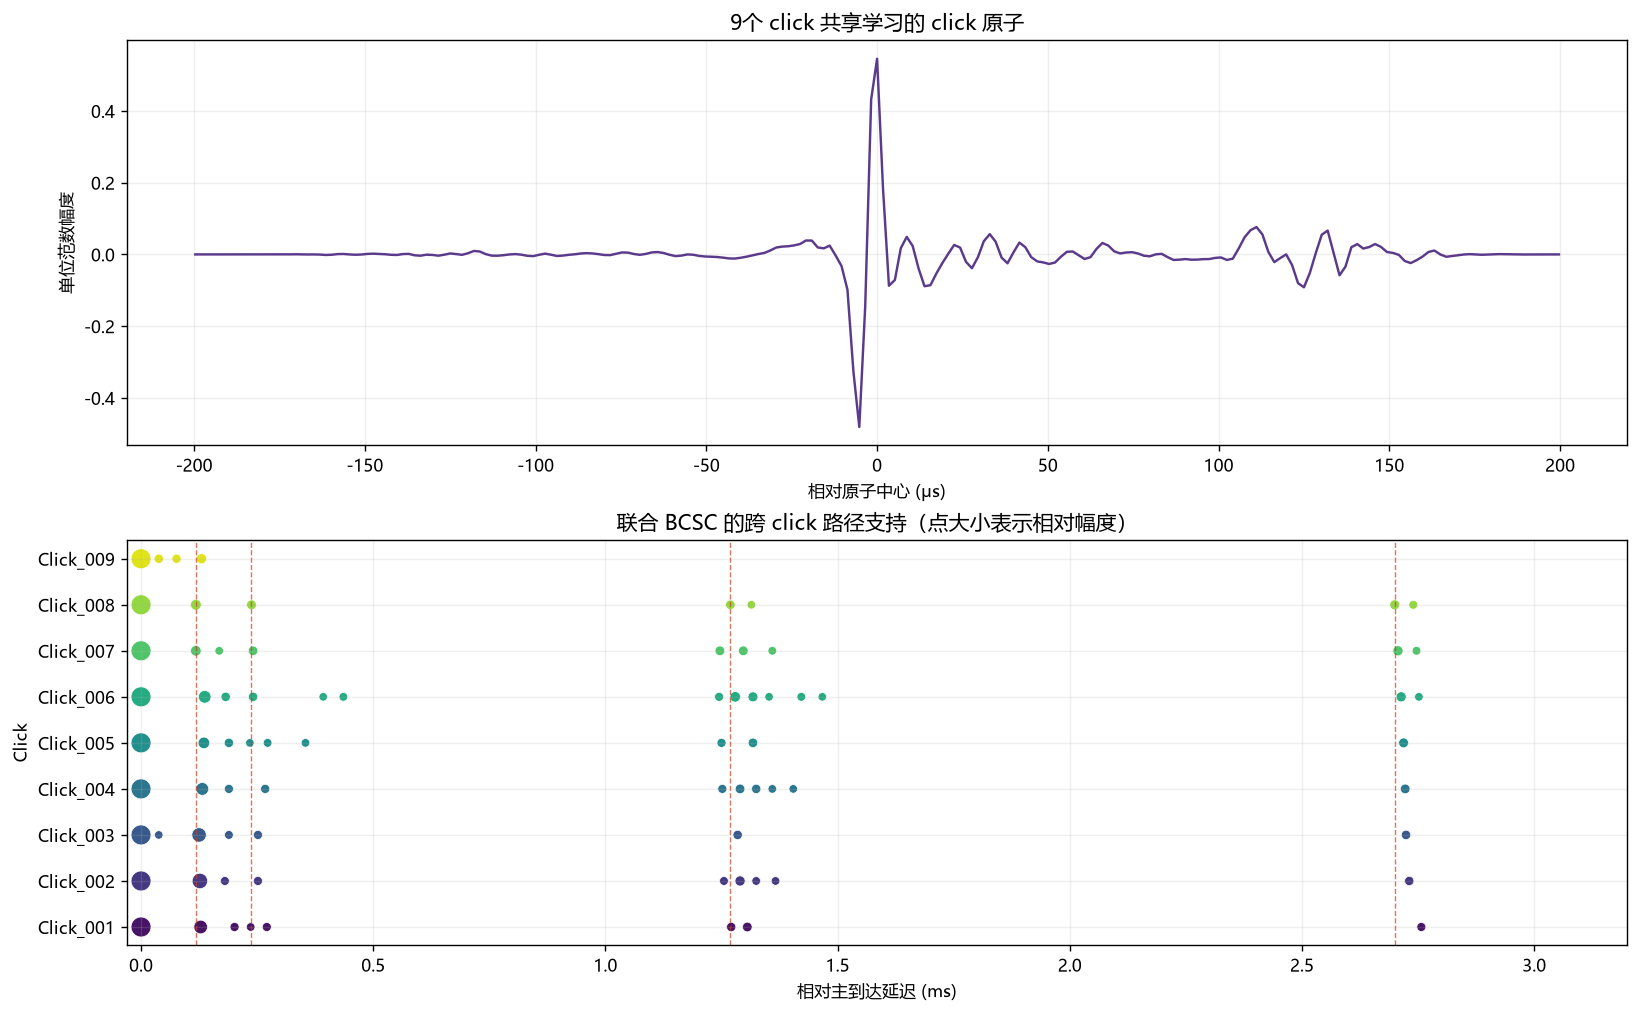

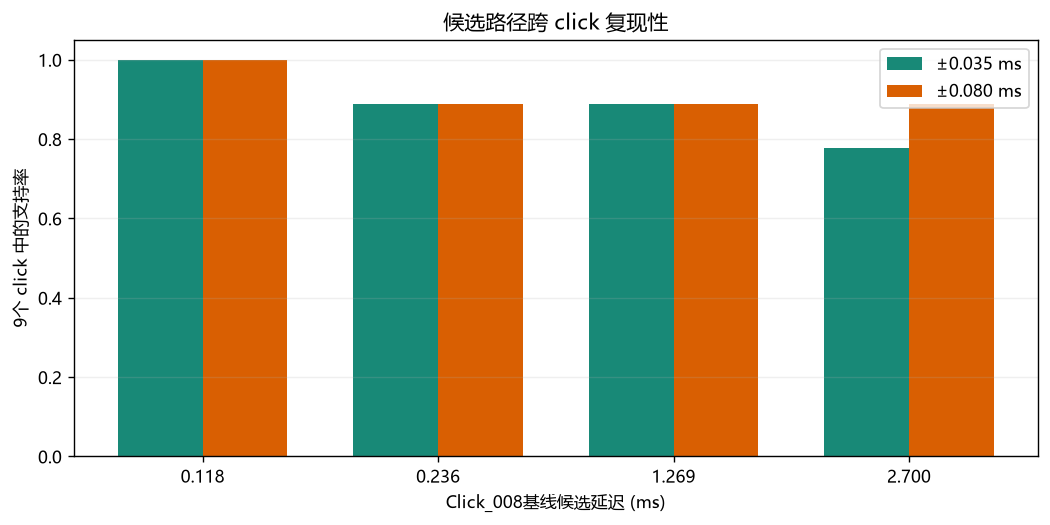

跨 click 支持率：
  0.1181 ms: 精确容差 100.0%; 宽容差 100.0%
  0.2361 ms: 精确容差 88.9%; 宽容差 88.9%
  1.2691 ms: 精确容差 88.9%; 宽容差 88.9%
  2.6997 ms: 精确容差 77.8%; 宽容差 88.9%


In [9]:
shared_atom, joint_codes, joint_estimates = joint_bcsc(
    signals, selected_atom_length, selected_lambda,
    FINAL_OUTER, FINAL_FISTA, FINAL_DICT,
)
overall.update(1)
overall.close()

joint_rows = []
joint_delay_lists = []
for label, signal, activation, estimate in zip(labels, signals, joint_codes, joint_estimates):
    metrics = summarize_fit(signal, shared_atom, activation, estimate)
    joint_delay_lists.append(np.asarray(metrics["delays_ms"]))
    joint_rows.append({"click": label, **metrics})

exact_support = []
broad_support = []
for reference in reference_delays:
    exact_support.append(np.mean([
        np.any(np.abs(delays - reference) <= PATH_MATCH_TOLERANCE_MS) for delays in joint_delay_lists
    ]))
    broad_support.append(np.mean([
        np.any(np.abs(delays - reference) <= 0.08) for delays in joint_delay_lists
    ]))

fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
atom_time_us = (np.arange(len(shared_atom)) - len(shared_atom) // 2) / fs * 1e6
axes[0].plot(atom_time_us, shared_atom, color="#5B3A8C", lw=1.4)
axes[0].set(xlabel="相对原子中心 (μs)", ylabel="单位范数幅度",
            title="9个 click 共享学习的 click 原子")

colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(labels)))
for row_idx, (label, activation, color) in enumerate(zip(labels, joint_codes, colors)):
    _, delays, amplitudes = extract_relative_peaks(activation, fs, len(shared_atom))
    keep = (delays >= 0) & (delays <= 3.2)
    sizes = 22 + 110 * np.clip(amplitudes[keep], 0, 1)
    axes[1].scatter(delays[keep], np.full(np.sum(keep), row_idx), s=sizes,
                    color=color, edgecolor="white", linewidth=0.4)
for reference in reference_delays:
    axes[1].axvline(reference, color="#C73E1D", ls="--", lw=0.8, alpha=0.7)
axes[1].set_yticks(range(len(labels)), labels)
axes[1].set(xlim=(-0.03, 3.2), xlabel="相对主到达延迟 (ms)", ylabel="Click",
            title="联合 BCSC 的跨 click 路径支持（点大小表示相对幅度）")
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(OUTPUT_DIR / "06_joint_click_shared_atom_paths.png", dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.3))
x = np.arange(len(reference_delays))
width = 0.36
ax.bar(x - width/2, exact_support, width, label="±0.035 ms", color="#188977")
ax.bar(x + width/2, broad_support, width, label="±0.080 ms", color="#D95F02")
ax.set_xticks(x, [f"{d:.3f}" for d in reference_delays])
ax.set(xlabel="Click_008基线候选延迟 (ms)", ylabel="9个 click 中的支持率",
       ylim=(0, 1.05), title="候选路径跨 click 复现性")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_cross_click_support.png", dpi=220, bbox_inches="tight")
plt.show()

print("跨 click 支持率：")
for reference, exact, broad in zip(reference_delays, exact_support, broad_support):
    print(f"  {reference:.4f} ms: 精确容差 {exact:.1%}; 宽容差 {broad:.1%}")


## 8. 数据导出与自动图文报告

报告的结论由下列预注册规则生成：

- 参数支持率：25组扫描中候选被检出的比例；
- 多初值支持率：8次优化中候选被检出的比例；
- 跨 click 支持率：共享原子模型中9个 click 的复现比例；
- 任何“稀疏/块稀疏/弥散”判断都是对当前带宽、时间窗和模型的诊断，不是对真实海洋信道的唯一证明。


In [10]:
grid_support = []
for ref_idx, reference in enumerate(reference_delays):
    grid_support.append(float(np.mean([
        np.isfinite(row["matched_delays_ms"][ref_idx]) for row in grid_results
    ])))

# 导出可重现的数据表
grid_csv = OUTPUT_DIR / "parameter_grid_results.csv"
with grid_csv.open("w", newline="", encoding="utf-8-sig") as handle:
    fields = ["atom_duration_ms", "lambda_ratio", "explained_variance", "k90", "k95",
              "block_k90", "tail_k90", "tail_block_k90", "tail_energy_fraction",
              "hoyer", "gini", "residual_atom_correlation", "n_detected_peaks"]
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    for row in grid_results:
        writer.writerow({field: row[field] for field in fields})

joint_csv = OUTPUT_DIR / "joint_click_metrics.csv"
with joint_csv.open("w", newline="", encoding="utf-8-sig") as handle:
    fields = ["click", "explained_variance", "k90", "k95", "block_k90",
              "tail_k90", "tail_block_k90", "tail_energy_fraction", "hoyer", "gini",
              "residual_atom_correlation", "n_detected_peaks"]
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    for row in joint_rows:
        writer.writerow({field: row[field] for field in fields})

# 避免强主到达将 K90 过度“压缩”：同时参考峰数、
# 单系数/分块稀疏度和残差相关。
if (best_metrics["n_detected_peaks"] <= 8 and best_metrics["k90"] <= 5
        and best_metrics["residual_atom_correlation"] < 0.08):
    channel_diagnosis = "主要能量在当前分辨率下可由少数离散激活表示，点稀疏BCSC基本合理。"
    next_model = "保留点稀疏BCSC，并继续报告参数、多初值和跨click稳定性。"
elif (best_metrics["block_k90"] <= max(5, math.ceil(best_metrics["k90"] / 3))
      and best_metrics["k90"] > best_metrics["block_k90"]):
    channel_diagnosis = "检出了较多相邻激活，但能量在少数时间块内集中：当前数据更支持成簇/块稀疏，而不是理想的点稀疏信道。"
    next_model = "下一版优先实现组稀疏/块稀疏BCSC；同时保留弥散残差诊断，暂不必立即增加多原子。"
else:
    channel_diagnosis = "激活能量需要较多时间块解释，且残差仍有结构，点稀疏假设不充分。"
    next_model = "下一版应实现‘稀疏强路径＋弥散混响尾’模型，并保留组稀疏结构。"

candidate_rows = []
for idx, reference in enumerate(reference_delays):
    candidate_rows.append({
        "reference_delay_ms": float(reference),
        "grid_support": grid_support[idx],
        "multistart_support": support_counts[idx],
        "cross_click_exact_support": exact_support[idx],
        "cross_click_broad_support": broad_support[idx],
    })

summary = {
    "record": "Voyage_Ori_01 / PulseTrain_014",
    "target_click": TARGET_CLICK,
    "sample_rate_hz": fs,
    "n_clicks": len(signals),
    "selected_configuration": {
        "atom_duration_ms": selected_atom_length / fs * 1e3,
        "lambda_ratio": selected_lambda,
        "selection_rule": "within 0.03 of maximum explained variance, then minimum block K90, residual-atom correlation, and maximum explained variance",
    },
    "best_multistart_metrics": best_metrics,
    "candidate_stability": candidate_rows,
    "joint_mean_explained_variance": float(np.mean([r["explained_variance"] for r in joint_rows])),
    "diagnosis": channel_diagnosis,
    "recommended_next_model": next_model,
    "limitations": [
        "single-channel blind factorization remains non-identifiable up to shift, sign, scale, and source/channel allocation",
        "candidate support is algorithmic reproducibility, not a posterior probability of a physical path",
        "the shared-atom model assumes broadly similar emitted/effective clicks across the train",
    ],
}
(OUTPUT_DIR / "diagnostic_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

# Markdown 图文报告
candidate_table = "\n".join(
    f"| {row['reference_delay_ms']:.4f} | {row['grid_support']:.0%} | "
    f"{row['multistart_support']:.0%} | {row['cross_click_exact_support']:.0%} | "
    f"{row['cross_click_broad_support']:.0%} |"
    for row in candidate_rows
)
joint_evs = np.asarray([row["explained_variance"] for row in joint_rows])
report = f'''# BCSC浅海信道稀疏性与可辨识性实验报告

## 一、实验目的

本报告检验 `Voyage_Ori_01 / PulseTrain_014` 中单原子BCSC的信道稀疏假设，并检查 `Click_008` 的早期结构是否对原子长度、稀疏强度和优化初值敏感。共处理{len(signals)}个click，采样率{fs:,} Hz。

![9个click波形](01_click_train_waveforms.png)

## 二、参数扫描

实验扫描5种原子长度（0.08–0.40 ms）和5种 `lambda_ratio`（0.01875–0.30），共25组。扫描最高解释方差为 **{max_explained:.3f}**。按预定折中规则选出：

- 原子长度：**{selected_atom_length / fs * 1e3:.4f} ms**；
- `lambda_ratio`：**{selected_lambda:.5f}**。

![参数网格指标](02_parameter_grid_metrics.png)

![候选路径参数支持](03_candidate_support_grid.png)

## 三、多初值稳定性

折中配置进行了8次不同初值优化。最优解的解释方差为 **{best_metrics['explained_variance']:.3f}**，$K_{{90}}$={best_metrics['k90']}，块$K_{{90}}$={best_metrics['block_k90']}，排除主到达±0.08 ms后的尾部$K_{{90}}$={best_metrics['tail_k90']}、尾部块$K_{{90}}$={best_metrics['tail_block_k90']}，Hoyer sparsity={best_metrics['hoyer']:.3f}。

![多初值稳定性](04_multistart_stability.png)

## 四、有效稀疏度与残差

{channel_diagnosis}

最优解残差与学习原子的最大归一化相关为 **{best_metrics['residual_atom_correlation']:.3f}**。该指标若较高，表示残差中仍存在单原子模型未解释的click样结构。

需要特别注意：自动折中规则选出的原子长度约0.40 ms，长于0.118 ms和0.236 ms候选延迟。因此该配置只能用于诊断，不能作为“原click已被唯一恢复”的证据。候选在长原子下消失或出现率降低，表示它对源/信道分配敏感。

![稀疏度与残差](05_effective_sparsity_and_residual.png)

## 五、跨click共享原子实验

9条记录的联合解释方差为 **{joint_evs.mean():.3f} ± {joint_evs.std():.3f}**（均值±标准差）。下图中红色虚线为 `Click_008` 原基线候选，散点为联合BCSC的各click激活。

![共享原子和跨click路径](06_joint_click_shared_atom_paths.png)

![跨click支持率](07_cross_click_support.png)

| Click_008参考延迟/ms | 25组参数支持 | 8次初值支持 | 跨click±0.035 ms | 跨click±0.080 ms |
|---:|---:|---:|---:|---:|
{candidate_table}

## 六、结论与下一步

**对当前数据的诊断：** {channel_diagnosis}

**模型建议：** {next_model}

候选路径应同时满足参数稳定、多初值稳定和跨click/跨通道一致后，才能升级为物理多径解释。本报告中的支持率是算法复现率，不是路径为真的后验概率。

## 七、限制

1. 单通道盲分解仍存在整体时移、符号、尺度和源/信道分配不唯一性。
2. 联合模型假设同一click train内的有效源波形近似共享；离轴角变化可破坏该假设。
3. 本实验没有真实发射click或已知信道，不能单独证明某一峰的物理来源。
4. 共享原子联合拟合与参数选择使用同一个click train，所以属于样本内诊断，不是独立外部验证。
'''
report_path = OUTPUT_DIR / "BCSC_shallow_water_diagnostic_report.md"
report_path.write_text(report, encoding="utf-8")

print(f"诊断摘要：{OUTPUT_DIR / 'diagnostic_summary.json'}")
print(f"图文报告：{report_path}")
print(f"参数网格：{grid_csv}")
print(f"跨click指标：{joint_csv}")
print("\n最终诊断：", channel_diagnosis)
print("下一步：", next_model)


诊断摘要：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_011_shallow_water_diagnostic_results\diagnostic_summary.json
图文报告：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_011_shallow_water_diagnostic_results\BCSC_shallow_water_diagnostic_report.md
参数网格：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_011_shallow_water_diagnostic_results\parameter_grid_results.csv
跨click指标：D:\Project_Github\Indo-Pacific-humpback-dolphin\18_多径提取算法\BCSC_011_shallow_water_diagnostic_results\joint_click_metrics.csv

最终诊断： 检出了较多相邻激活，但能量在少数时间块内集中：当前数据更支持成簇/块稀疏，而不是理想的点稀疏信道。
下一步： 下一版优先实现组稀疏/块稀疏BCSC；同时保留弥散残差诊断，暂不必立即增加多原子。
